# Tools - reducing graph (spectral embedding)

This notebook shows how to reduce (coarsen) a graph by via spectral embedding and K-means. This algorithm computes a lighter graph, with less nodes and edges, by regrouping the nodes of the original graph in clusters, which are the output nodes, and by linking these clusters according to the edges present in the original graph.

*Note. Presented tool works on `networkx.Graph` objects. A `KGraph` object `kg` can be defined from a `networkx.Graph` graph `g` with `kg = kn.from_networkx(g)`.*

In [1]:
import networkx as nx
import numpy as np 
import matplotlib.pyplot as plt
# import scipy
import time

In [2]:
# Choose matplotlib backend
# -------------------------
# 'inline' : inline plot (non-interactive)
# 'widget' : interactive plot
# 'tk'     : plot in a pop-up window (interactive)
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
# get_ipython().run_line_magic('matplotlib', 'widget')
# get_ipython().run_line_magic('matplotlib', 'tk')

# Or simply:
# %matplotlib inline
# %matplotlib widget
# %matplotlib tk


In [3]:
import pyvista as pv

# Choose backend for pyvista with jupyter
# ---------------------------------------
pv.set_jupyter_backend('static') # static plots
# pv.set_jupyter_backend('trame')  # 3D-interactive plots

# Notes:
# -> ignored if run in a standard python shell
# -> use keyword argument "notebook=False" in Plotter() to open figure in a pop-up window

In [4]:
import karstnet as kn
print(f'Karstnet version: {kn.__version__}')

Karstnet version: 1.4.6


In [5]:
# Define a function to generate a segmented color map
import matplotlib

def seg_cmap(ncol, cmap=plt.cm.rainbow, t0=0.1, t1=0.9):
    """Function to define a segmented color map."""
    # - extract some colors from the color map `cmap`
    colors = [cmap(i) for i in range(int(t0*cmap.N), int(t1*cmap.N))]
    # - create the new segmented color map
    segmented_cmap = matplotlib.colors.LinearSegmentedColormap.from_list('Segmented cmap', colors, ncol)
    return segmented_cmap    

## Reduce a graph via spectral embedding and K-means

The function `kn.tools.reduce_graph_spectral_kmeans` is used to reduce a connected graph via spectral embedding and K-means.

Consider an input graph `g` (`networkx.Graph` object) that is assumed to be connected (one connected component). The following procedure is applied.

### 1. Spectral embedding
The `n` graph nodes are embedded in a space of dimension $m$ (parameter `embedding_space_dim`) as follows. Let $u_j$ and $\lambda_j$, $j=0, \ldots, n-1$ be the eigenvectors and eigenvalues of the Laplacian matrix of `g`, with $0 = \lambda_0 < \lambda_1 \leq \ldots \lambda_{n-1}$. The graph node of index $i$ ($i = 0, \ldots, n-1$) is represented by the point of coordinate $(u_1(i), \ldots, u_m(i))$; i.e. with $U$ the $n\times m$ matrix whose columns are the first eigenvectors with strictly positive eigenvalues of the Laplacian matrix, the rows of $U$ are the points representing the graph nodes.

### 2. K-means (with coodinate weight / rescaling) in the embedding space 
Then, the K-means algorithm is applied on the points representing the graph nodes in the embedding space, with the coordinate $j$ re-scaled (weighted) by $\lambda_j^{-1/2}$, i.e. the points $(\lambda_1^{-1/2}\cdot u_1(i), \ldots, \lambda_m^{-1/2}\cdot u_m(i))$ are considered. The number of clusters (number of nodes in the output graphs) is given by the parameter `nclusters`.

### 3. Building the output graph (`g_red`)
The clusters resulting from K-means are retrieved and form the new nodes (super-nodes) in the output graph. The node attributes (properties, e.g. position) in the output graph (if any) are defined according to the keyword argument `node_attr_mode` from the attributes of the original graph nodes in the cluster:
- mode: 'mean' : the mean of attribute values in the cluster
- mode: 'medoid' : the attribute of the medoid node of the cluster; in that case the cluster must be connected, i.e. must have one connected component; the medoid of the subgraph of the input graph induced by the nodes in the cluster is computed, where the medoid is the node realizing the minimum of the sum of the shortest path lengths wrt. inverse of edge weight (i.e., wrt. resistances (instead of conductances determining the Laplacian matrix)) to any other node

Finally an edge is set between two super-nodes if the two corresponding clusters are linked in the original graph.

### Set pre-defined clusters
Moreover, using the parameter `fixed_cluster_dict` (optional), one can define fixed clusters: this parameter is a dictionary where the keys are input graph node labels, and the values integer ids; the id 0 is the default id attached to any node that is not listed in the keys; the nodes with the same id > 0 form a pre-defined cluster. This can be used to add some control on the graph reduction.
      
### Optional outputs
The function `kn.tools.reduce_graph_spectral_kmeans` returns the reduced graph, and optionally:
- if parameter `return_new_id_dict=True`: a dictionary where the keys are the node labels of the input graph and the values are the corresponding node labels in the output graph, i.e. the id of the cluster containing the node of the input graph
- if parameter `return_orig_id_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the lists of the node labels of the input graph in the corresponding clusters
- if parameter `return_cluster_medoid_id_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the node ids (labels) in the input graph of the cluster medoids (see above);
- if parameter `return_cluster_diameter_dict=True`: a dictionary where the keys are the node labels of the output graph and the values are the diameters of the cluster (box), i.e. the maximal distance (in the original graph, wrt. inverse of edge edge weight) between two nodes in the cluster


## Simple example on a small graph 2D
A 2D example - a graph generated from a Delaunay triangulation of points.

In [6]:
# Options for plot of 2D graph
options = {
    'node_size'   : 150,         # node size
    'linewidths'  : 1,           # node border width       
    'edgecolors'  : 'gray',      # node border color
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

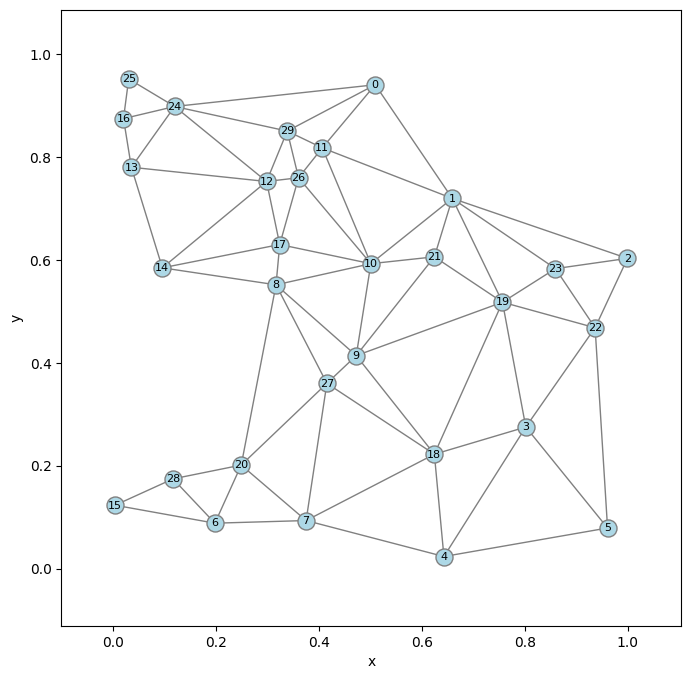

In [7]:
# Number of points and seed
npoints = 30
seed = 35306

# Generate random points uniformly in [0, 1] x [0, 1]
np.random.seed(seed)
points = np.random.random(size=(npoints, 2))

# Generate 2D graph from Delaunay triangulation of the points,
# edges whose length are less (resp. greater) than a mininmal (resp. maximal) valuse are removed
g = kn.misc.graph_from_delaunay_tri(points,min_edge_len=0.01, max_edge_len=0.4)

# Keep the largest connected component
g = kn.utils.get_list_of_connected_components(g, order='descending', renumbering_nodes=True)[0]

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

- Add a node with a string as label to check that the developed algorithms work property

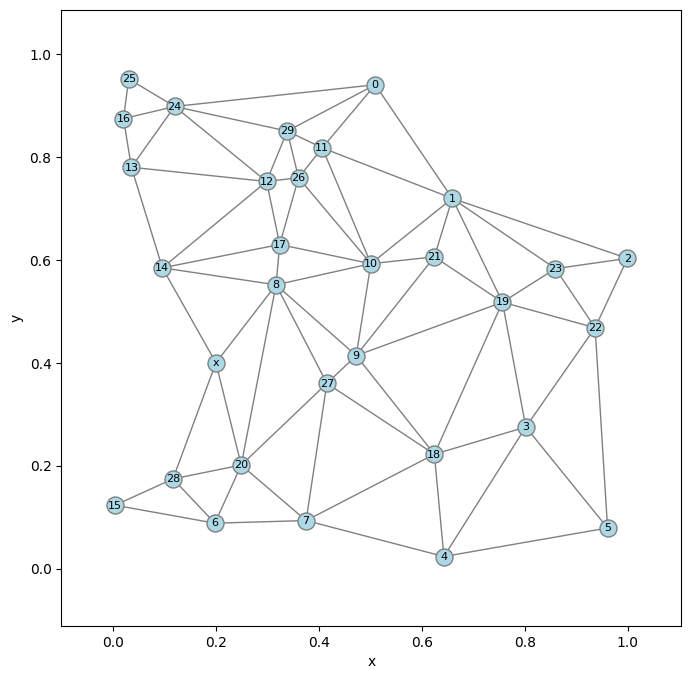

In [8]:
# Add a node with label 'x' and some edges
g.add_node('x')
g.nodes['x']['pos'] = np.array([0.2, 0.4])
g.add_edges_from([('x', i) for i in [8, 14, 28, 20]])

# Plot the graph
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(g, **options)
plt.show()

### Set edge weight (conductance $\omega$)

In [9]:
# Set edge conductance in the original graph
# ------------------------------------------

# Inverse of edge length
w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Plot conductances

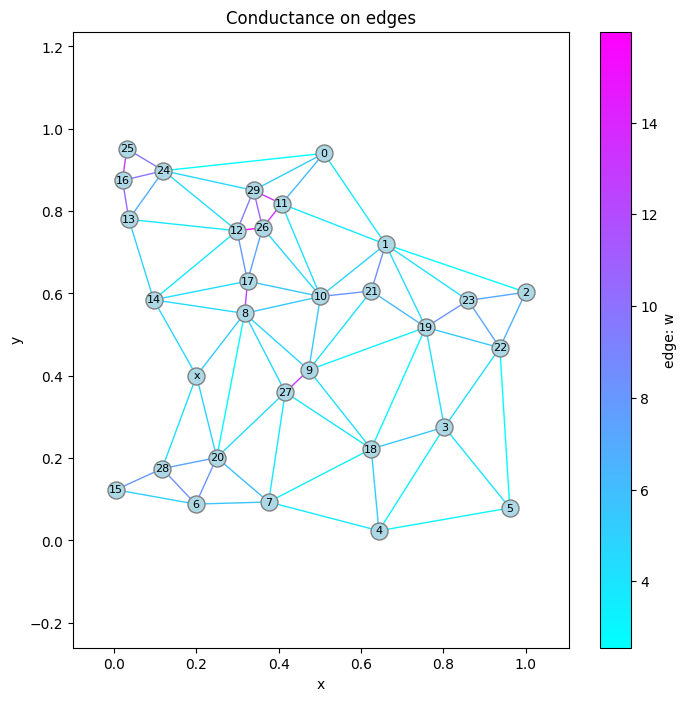

In [10]:
plt.figure(figsize=(8, 8))
kn.view.plot_graph2d(
    g,
    node_attr=None, 
    edge_attr='w', edge_cmap='cool',
    **options)
plt.title('Conductance on edges')
plt.show()

### Reduce (coarsen) graph via spectral embedding and K-means

In [11]:
# Compute reduced graph `g_red` and additional dictionaries
embedding_space_dim = 2
nclusters = 7
edge_weight = 'w'
node_attr_mode = 'mean'
# node_attr_mode = 'medoid'
fixed_cluster_dict = None

t1 = time.time()
g_red, new_id_dict, orig_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_spectral_kmeans(
        g, 
        nclusters,
        embedding_space_dim,
        edge_weight=edge_weight,
        node_attr_mode=node_attr_mode,
        fixed_cluster_dict=fixed_cluster_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=8932,
        verbose=1)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# Set properties to nodes in input graph
nx.set_node_attributes(g, new_id_dict, 'new_id')

# Set properties to nodes in reduced graph
nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')

Reduce (coarsen) graph via spectral embedding and K-means...
Get or compute eigenvalues and eigenvectors of the Laplacian matrix...
Apply K-means in the spectral embedding space (dim=2, nclusters=7)...
Build the output graph (reduced / coarse graph) ...
Elapsed time : 0.0076 sec


In [12]:
# Options for plot of 2D graph
options_g = {
    'node_size'   : 150,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    # 'cmap'        : 'tab20c',    # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,       # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

options_g_red = {
    'node_size'   : 150,         # node size
    'linewidths'  : 2,           # node border width       
    'edgecolors'  : 'tab:red',   # node border color
    'node_color'  : 'none',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'tab:red',   # edge color (default - if no attribute is specified or for nan values)
    # 'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Color map and bounds for "new id"
cmap = seg_cmap(g_red.number_of_nodes(), cmap=plt.cm.tab20c)
vmin, vmax =-0.5, g_red.number_of_nodes()-0.5


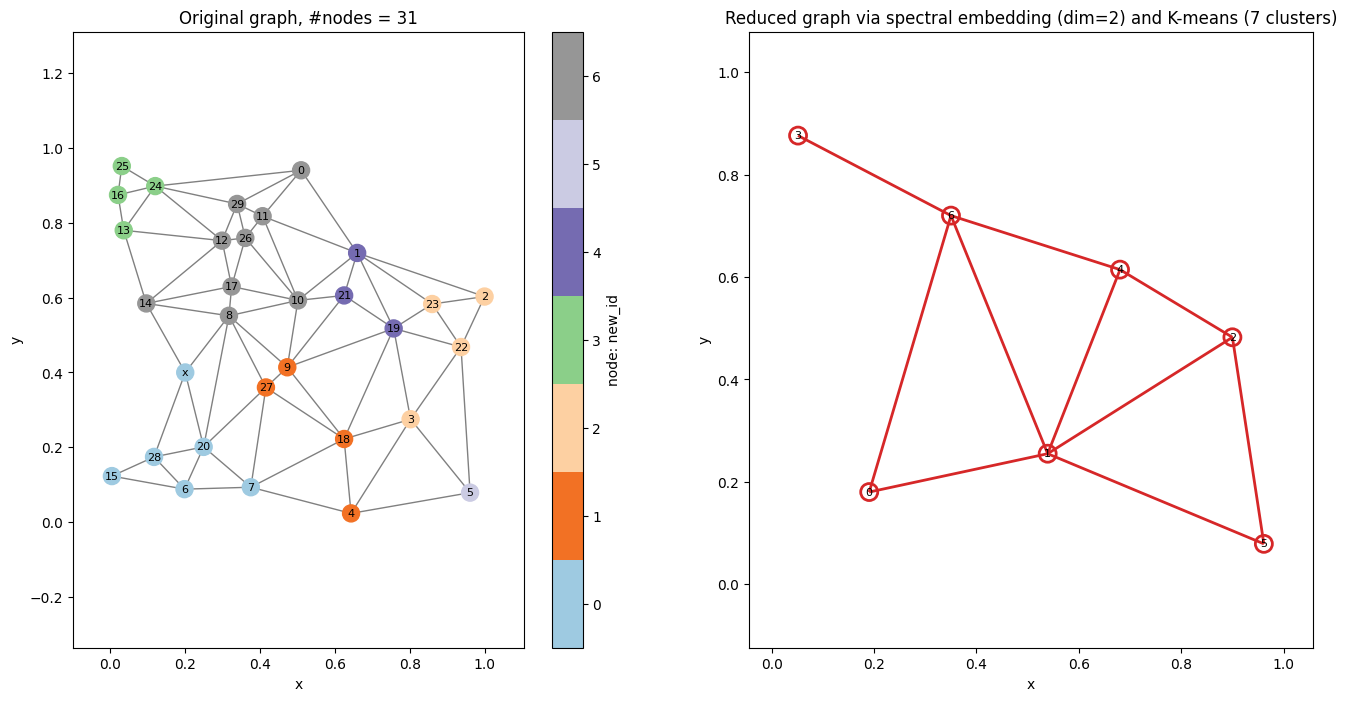

In [13]:
plt.subplots(1,2, figsize=(16, 8))

plt.subplot(1,2,1)
kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g)
plt.title(f'Original graph, #nodes = {g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_red, with_labels=True, **options_g_red)
plt.title(f'Reduced graph via spectral embedding (dim={embedding_space_dim}) and K-means ({nclusters} clusters)')

plt.show()


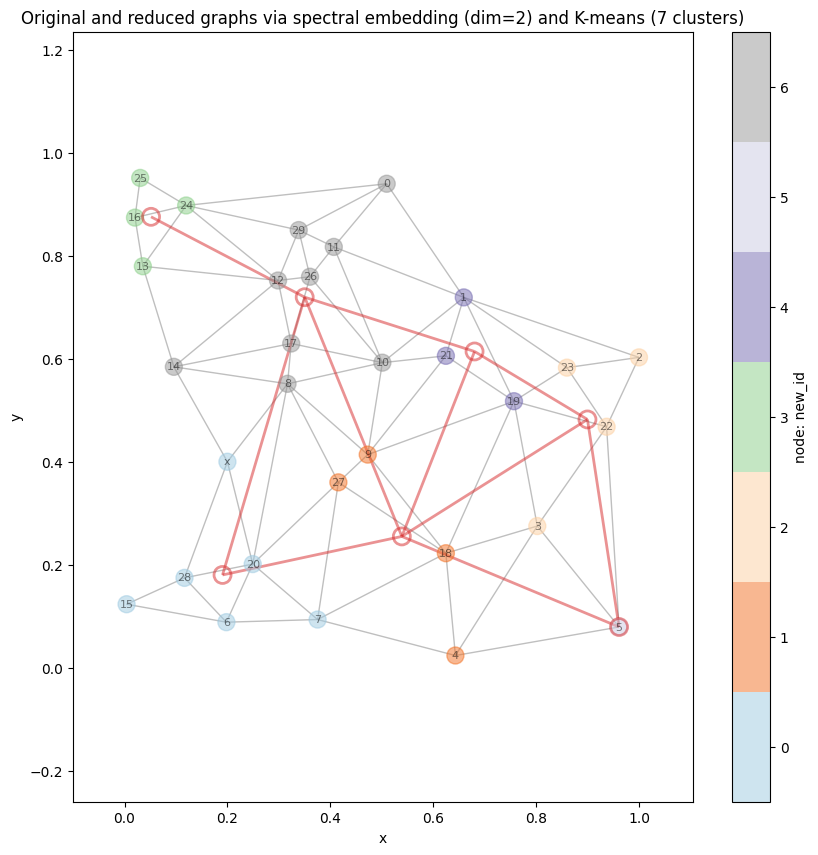

In [14]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=.5)
kn.view.plot_graph2d(g_red, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs via spectral embedding (dim={embedding_space_dim}) and K-means ({nclusters} clusters)')

plt.show()


#### Optional outputs of the function `kn.tools.reduce_graph_spectral_kmeans`

In [15]:
# orig_id_dict: mapping from new node label to original node label
orig_id_dict

{0: [6, 7, 15, 20, 28, 'x'],
 1: [4, 9, 18, 27],
 2: [2, 3, 22, 23],
 3: [13, 16, 24, 25],
 4: [1, 19, 21],
 5: [5],
 6: [0, 8, 10, 11, 12, 14, 17, 26, 29]}

In [16]:
# new_id_dict: mapping from original node label to new node label
new_id_dict

{0: 6,
 1: 4,
 2: 2,
 3: 2,
 4: 1,
 5: 5,
 6: 0,
 7: 0,
 8: 6,
 9: 1,
 10: 6,
 11: 6,
 12: 6,
 13: 3,
 14: 6,
 15: 0,
 16: 3,
 17: 6,
 18: 1,
 19: 4,
 20: 0,
 21: 4,
 22: 2,
 23: 2,
 24: 3,
 25: 3,
 26: 6,
 27: 1,
 28: 0,
 29: 6,
 'x': 0}

In [17]:
# medoid_id_dict: mapping from new node label to cluster medoid node label in the original graph
medoid_id_dict

{0: 20, 1: 18, 2: 22, 3: 24, 4: 19, 5: 5, 6: 10}

In [18]:
# cluster_diameter_dict: mapping from new node label to diameter of the cluster in the original graph
cluster_diameter_dict

{0: 13.420467237981097,
 1: 9.09845987557468,
 2: 11.47789301142184,
 3: 16.4993064455647,
 4: 8.421235502607054,
 5: 0,
 6: 18.419004680655984}

#### Changing position of the output graph nodes

In [19]:
# Set position of nodes in reduced graph to the position of the medoids of the clusters
g_red_medoid = g_red.copy()

for u in g_red_medoid.nodes():
    g_red_medoid.nodes[u]['pos'] = g.nodes[medoid_id_dict[u]]['pos']

# Note: `g_red_medoid` may also be obtained by running `kn.tools.reduce_graph_spectral_kmeans` as above but with parameter `node_attr_mode='medoid'`.

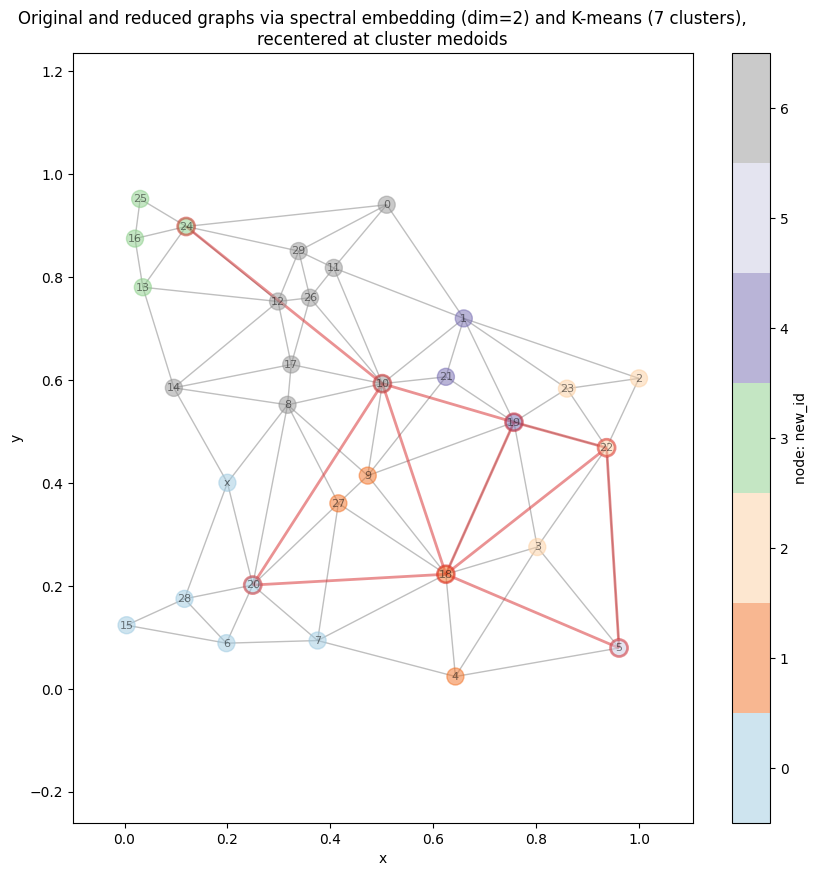

In [20]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=.5)
kn.view.plot_graph2d(g_red_medoid, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'Original and reduced graphs via spectral embedding (dim={embedding_space_dim}) and K-means ({nclusters} clusters),\nrecentered at cluster medoids')

plt.show()


### Graphs in spectral embedding space


In [21]:
# embedding_space_dim = 2 # already defined above
# edge_weight = 'w'       # already defined above

# Compute (first) eigen values and eigen vectors of the Laplacian matrix, used for spectral embedding
k = embedding_space_dim+1
eigval, eigvec = kn.tools.laplacian_eigs(g, edge_weight=edge_weight, k=k)
# Note: `eigval` and `eigvec` can be passed directly as keyword arguments to the function `kn.tools.reduce_graph_spectral_kmeans`

# Set correspondance (mapping) between node label and node index
node_label2index = {u:i for i, u in enumerate(g.nodes())}
node_index2label = {i:u for i, u in enumerate(g.nodes())}

# # or
# node_label2index = kn.utils.get_node_label2index_dict(g)
# node_index2label = kn.utils.get_node_index2label_dict(g)

# Set eigenvectors (coordinates in the spectral embedding space) as node attributes
for j in range(1, embedding_space_dim+1):
    d = {u:eigvec[node_label2index[u], j] for u in g.nodes()}
    # # or:
    # d = {node_index2label[i]:eigvec[i, j] for i in range(g.number_of_nodes())}

    nx.set_node_attributes(g, d, f'eig_{j}')


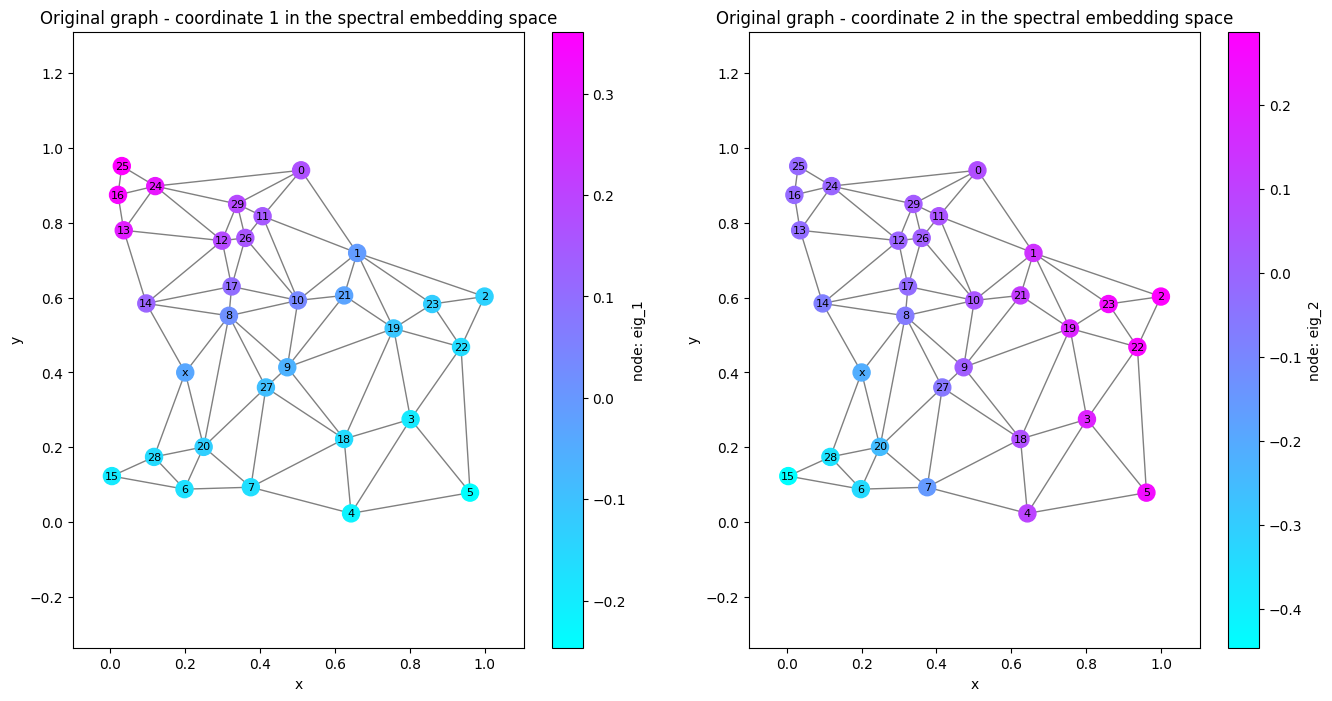

In [22]:
# Show coordinate in the spectral embedding space
plt.subplots(1,2, figsize=(16, 8))

for j in range(1, embedding_space_dim+1):
    plt.subplot(1,2,j)
    kn.view.plot_graph2d(g, node_attr=f'eig_{j}', cmap='cool', **options_g)
    plt.title(f'Original graph - coordinate {j} in the spectral embedding space')

plt.show()


In [23]:
# Define embedded graph - original graph
# --------------------------------------
g_emb = g.copy()

# Set node position
d = {u:eigvec[node_label2index[u], 1:3] for u in g.nodes()}
# # or:
# d = {node_index2label[i]:eigvec[i, 1:3] for i in range(g.number_of_nodes())}
nx.set_node_attributes(g_emb, d, 'pos')

# Define embedded graph - reduced graph - medoid mode
# ---------------------------------------------------
g_red_medoid_emb = g_red_medoid.copy()

# Set node position
d = {u:eigvec[node_label2index[medoid_id_dict[u]], 1:3] for u in g_red_medoid.nodes()}
nx.set_node_attributes(g_red_medoid_emb, d, 'pos')

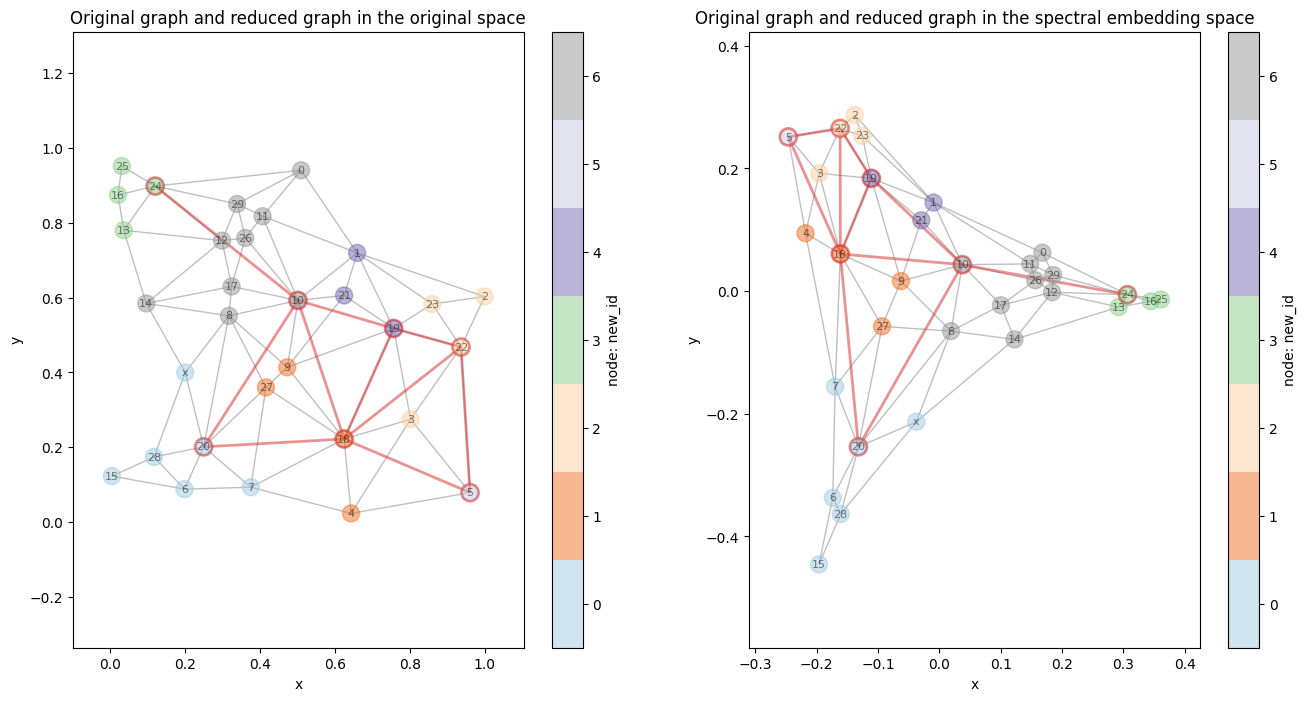

In [24]:
# Show graph in the original space and in the spectral embedding space
plt.subplots(1,2, figsize=(16, 8))

plt.subplot(1,2,1)
kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=0.5)
kn.view.plot_graph2d(g_red_medoid, with_labels=False, **options_g_red, alpha=.5)
plt.title('Original graph and reduced graph in the original space')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_emb, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=0.5)
kn.view.plot_graph2d(g_red_medoid_emb, with_labels=False, **options_g_red, alpha=.5)
plt.title('Original graph and reduced graph in the spectral embedding space')

plt.show()


### Fixing some nodes in the input graph (setting pre-defined clusters)
With the parameter `fixed_cluster_dict` (optional), one can define fixed clusters: this parameter is a dictionary where the keys are input graph node labels, and the values integer ids; the id 0 is the default id attached to any node that is not listed in the keys; the nodes with the same id > 0 form a pre-defined cluster.

In particular, one can pre-define clusters of one node, which implies that such a node will be fixed in the reduced graph.

In [25]:
# Compute reduced graph `g_red` and additional dictionaries
embedding_space_dim = 2
nclusters = 7
edge_weight = 'w'
node_attr_mode = 'mean'
# node_attr_mode = 'medoid'
fixed_cluster_dict = {15: 1, 5: 2, 2: 3, 25: 4}  # Fix nodes 15, 5, 2, and 25 in the reduced graph

t1 = time.time()
g_red, new_id_dict, orig_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_spectral_kmeans(
        g, 
        nclusters,
        embedding_space_dim,
        edge_weight=edge_weight,
        node_attr_mode=node_attr_mode,
        fixed_cluster_dict=fixed_cluster_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=8932,
        verbose=1)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# Set properties to nodes in input graph
nx.set_node_attributes(g, new_id_dict, 'new_id')

# Set properties to nodes in reduced graph
nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')

Reduce (coarsen) graph via spectral embedding and K-means...
Get or compute eigenvalues and eigenvectors of the Laplacian matrix...
Apply K-means in the spectral embedding space (dim=2, nclusters=7)...
Build the output graph (reduced / coarse graph) ...
Elapsed time : 0.0084 sec


In [26]:
# Options for plot of 2D graph
options_g = {
    'node_size'   : 150,         # node size
    'node_color'  : 'lightblue', # node color (default - if no attribute is specified or for nan values)
    # 'cmap'        : 'tab20c',    # node color map (for attribute values)
    'width'       : 1,           # edge width
    'edge_color'  : 'gray',      # edge color (default - if no attribute is specified or for nan values)
    'with_labels' : True,       # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

options_g_red = {
    'node_size'   : 150,         # node size
    'linewidths'  : 2,           # node border width       
    'edgecolors'  : 'tab:red',   # node border color
    'node_color'  : 'none',      # node color (default - if no attribute is specified or for nan values)
    'width'       : 2,           # edge width
    'edge_color'  : 'tab:red',   # edge color (default - if no attribute is specified or for nan values)
    # 'with_labels' : True,        # show node labels ?
    'font_size'   : 8,           # font size for labels
    #
    # axes
    'show_ticks'  : True,        # show ticks ?
    'axis_equal'  : True         # aspect ratio equal ?
}

# Color map and bounds for "new id"
cmap = seg_cmap(g_red.number_of_nodes(), cmap=plt.cm.tab20c)
vmin, vmax =-0.5, g_red.number_of_nodes()-0.5


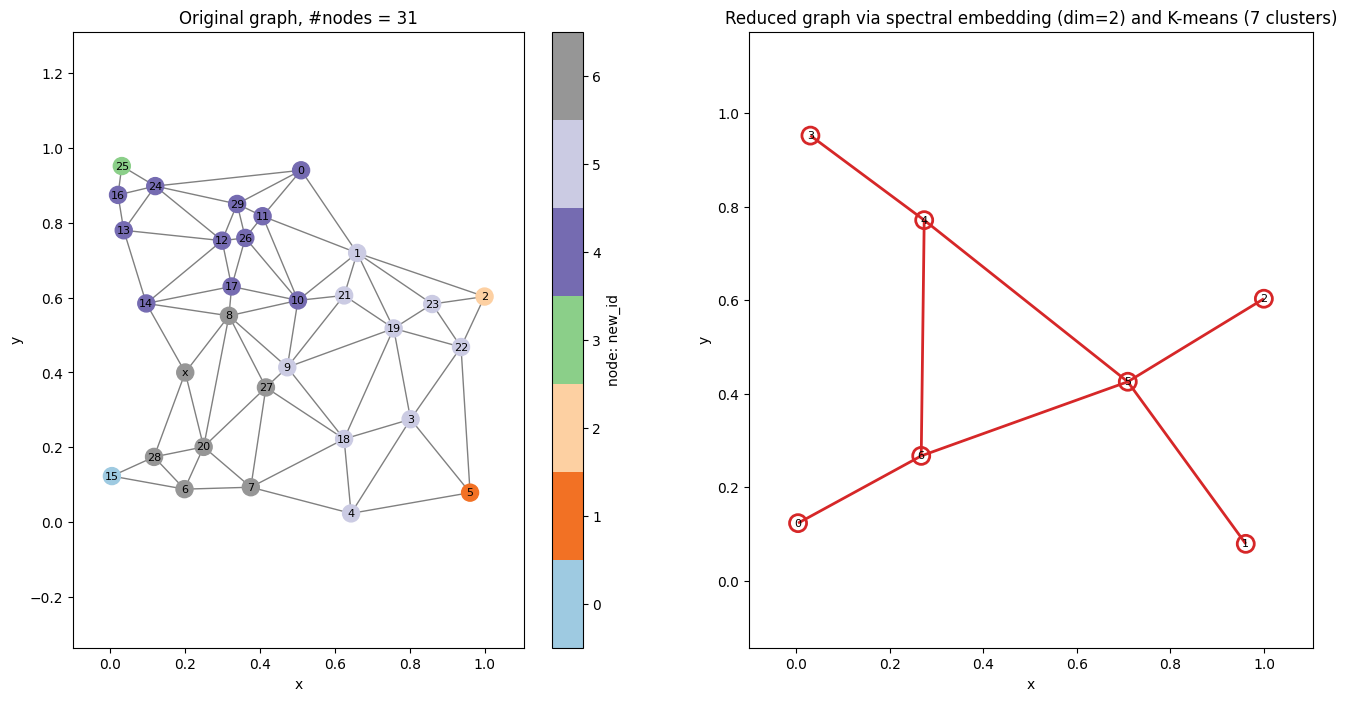

In [27]:
plt.subplots(1,2, figsize=(16, 8))

plt.subplot(1,2,1)
kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g)
plt.title(f'Original graph, #nodes = {g.number_of_nodes()}')

plt.subplot(1,2,2)
kn.view.plot_graph2d(g_red, with_labels=True, **options_g_red)
plt.title(f'Reduced graph via spectral embedding (dim={embedding_space_dim}) and K-means ({nclusters} clusters)')

plt.show()


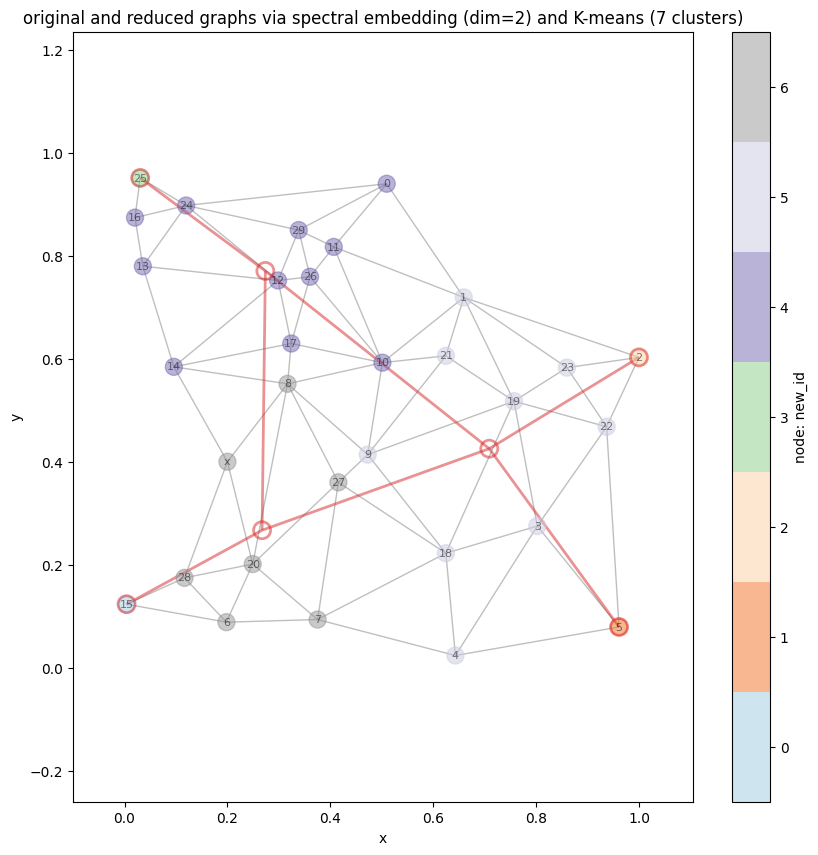

In [28]:
plt.figure(figsize=(10, 10))

kn.view.plot_graph2d(g, node_attr='new_id', cmap=cmap, vmin=vmin, vmax=vmax, **options_g, alpha=0.5)
kn.view.plot_graph2d(g_red, with_labels=False, **options_g_red, alpha=.5)
plt.title(f'original and reduced graphs via spectral embedding (dim={embedding_space_dim}) and K-means ({nclusters} clusters)')

plt.show()


## 3D example - real karst network

Example with the real karst network of Combe Bryon (Leysin, Switzerland).

### Load karst network
Load karst network from csv files. 

*Note. Other format are handled by karstnet.*

In [29]:
# Load KGraph object
basename = f'../data/CombeBryon_csv/CombeBryon'

kg = kn.from_csv(
        basename,
        suffix_nodes='_node_pos.csv', 
        suffix_edges='_edges.csv', 
        delimiter_nodes=';',  
        delimiter_edges=';',
        import_node_scalar_properties=True,
        import_edge_scalar_properties=True,
        verbose=True)

# Extract original graph
g = kg.graph


This network contains 1 connected components
Karstnet graph successfully created from csv files !



In [30]:
# # Equivalent 
# # ----------
# # - define networkx graph
# g = kn.io.networkx_from_csv(
#         basename,
#         suffix_nodes='_node_pos.csv', 
#         suffix_edges='_edges.csv', 
#         delimiter_nodes=';',  
#         delimiter_edges=';',
#         import_node_scalar_properties=True,
#         import_edge_scalar_properties=True,
#         verbose=True)
# # - then instanciate KGraph with
# kg = kn.from_networkx(g)
# # or
# Kg = kn.KGraph(None, None, None, networkx_graph=g, verbose=True)

### Plot original graph

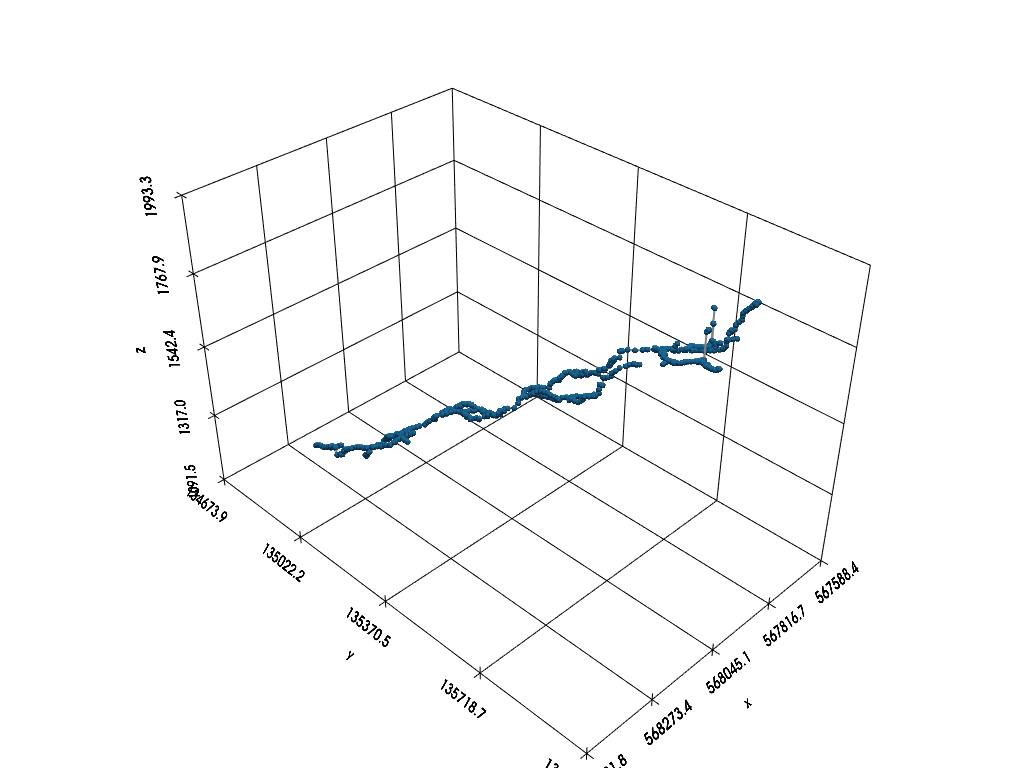

In [31]:
#pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)

pp.show()


### Set edge weight (conductance $\omega$)

In [32]:
# Set edge conductance in the original graph
# ------------------------------------------

# Inverse of edge length
w = kn.utils.get_edge_length_dict(g, 'pos', exponent=-1)
# w = {e: 1.0/np.sqrt(np.sum((np.asarray(g.nodes[e[0]]['pos']) - np.asarray(g.nodes[e[1]]['pos']))**2)) for e in g.edges()} # Equiv.

nx.set_edge_attributes(g, w, 'w')


### Reduce (coarsen) graph via spectral embedding and K-means

In [33]:
# Compute reduced graph `g_red` and additional dictionaries
embedding_space_dim = 200 #g.number_of_nodes()-1
nclusters = g.number_of_nodes()//3
edge_weight = 'w'
node_attr_list = ['pos']
node_attr_mode = 'mean'
# node_attr_mode = 'medoid'
fixed_cluster_dict = None

t1 = time.time()
g_red, new_id_dict, orig_id_dict, medoid_id_dict, cluster_diameter_dict = \
    kn.tools.reduce_graph_spectral_kmeans(
        g, 
        nclusters,
        embedding_space_dim,
        edge_weight=edge_weight,
        node_attr_list=node_attr_list,
        node_attr_mode=node_attr_mode,
        fixed_cluster_dict=fixed_cluster_dict,
        return_new_id_dict=True, 
        return_orig_id_dict=True,
        return_medoid_id_dict=True,
        return_cluster_diameter_dict=True,
        seed=893,
        verbose=1)
t2 = time.time()
print(f'Elapsed time : {t2-t1:.2g} sec')

# # Set properties to nodes in input graph
# nx.set_node_attributes(g, new_id_dict, 'new_id')

# # Set properties to nodes in reduced graph
# nx.set_node_attributes(g_red, orig_id_dict, 'orig_id')
# nx.set_node_attributes(g_red, medoid_id_dict, 'medoid_id')
# nx.set_node_attributes(g_red, cluster_diameter_dict, 'cluster_diameter')

Reduce (coarsen) graph via spectral embedding and K-means...
Get or compute eigenvalues and eigenvectors of the Laplacian matrix...
Apply K-means in the spectral embedding space (dim=200, nclusters=202)...
Build the output graph (reduced / coarse graph) ...
Elapsed time : 0.44 sec


### Plot result

- original graph and reduced graph on two separate figures

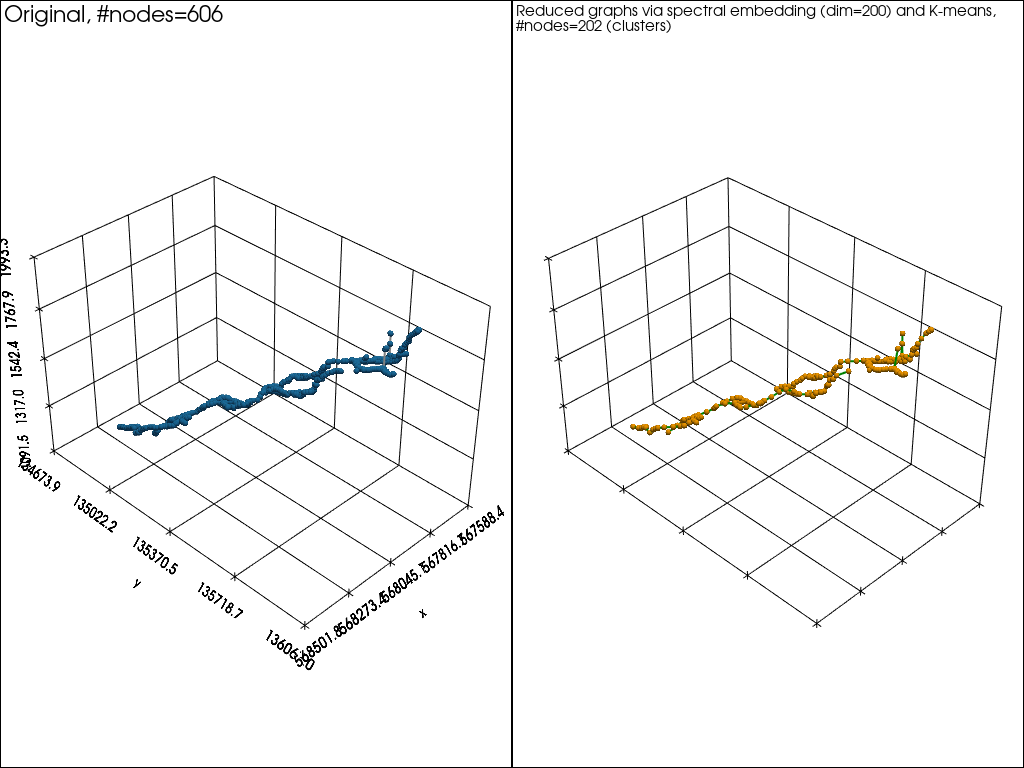

In [34]:
#pp = pv.Plotter(shape=(1, 2), notebook=False) # plot in a pop-up window
pp = pv.Plotter(shape=(1, 2))

pp.subplot(0, 0)
kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue'},
    options_edges={'line_width': 2, 'color': 'gray'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
pp.add_text(f'Original, #nodes={g.number_of_nodes()}', font_size=12)

pp.subplot(0, 1)
kn.view.pv_plot_graph(
    g_red, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'orange'},
    options_edges={'line_width': 2, 'color': 'green'},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
pp.add_text(f'Reduced graphs via spectral embedding (dim={embedding_space_dim}) and K-means,\n#nodes={g_red.number_of_nodes()} (clusters)', font_size=12)

pp.link_views()
pp.show()


- original graph and reduced graph on same figure

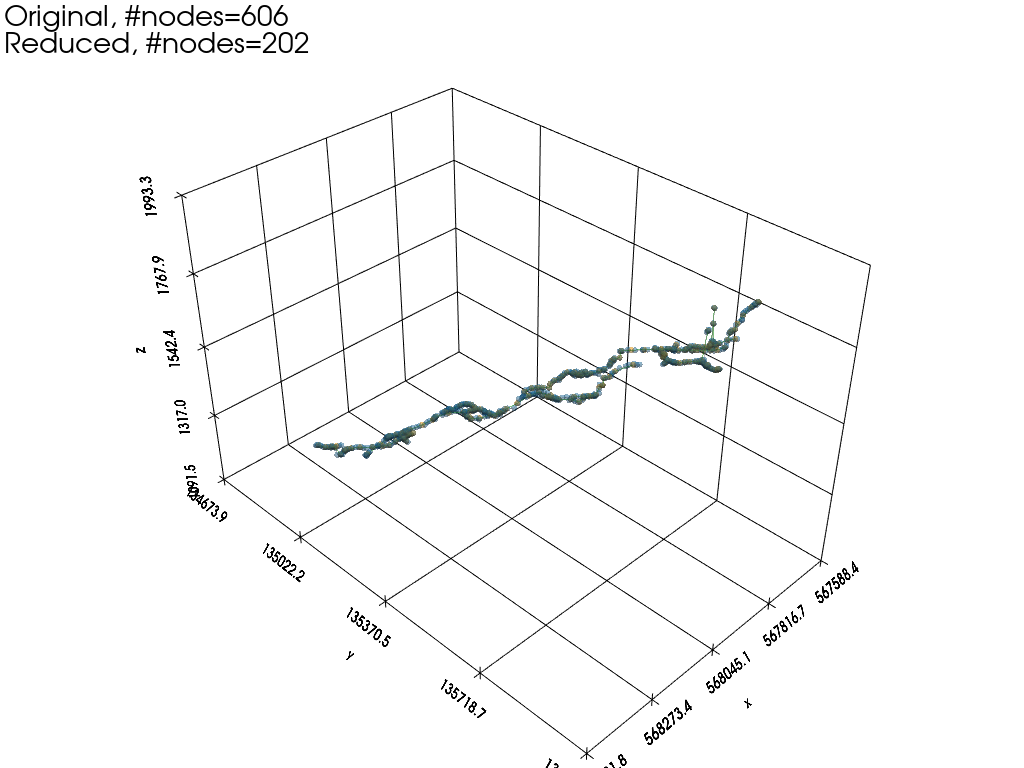

In [35]:
# pp = pv.Plotter(notebook=False) # plot in a pop-up window
pp = pv.Plotter()

kn.view.pv_plot_graph(
    g, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'tab:blue', 'opacity': 0.5},
    options_edges={'line_width': 1, 'color': 'gray', 'opacity': 0.5},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)
kn.view.pv_plot_graph(
    g_red, 
    plotter=pp,
    options_nodes={'point_size': 6, 'color': 'orange', 'opacity': 0.5},
    options_edges={'line_width': 1, 'color': 'green', 'opacity': 0.5},
    show_grid=True,
    options_show_grid={'font_size': 12, 'padding': 0.2},
    with_labels=False
)

pp.add_text(f'Original, #nodes={g.number_of_nodes()}\nReduced, #nodes={g_red.number_of_nodes()}', font_size=12)

pp.show()


### Show first eigenvectors and eigenvalues of Laplacian of input graph


In [36]:
embedding_space_dim_tmp = 3
edge_weight = 'w'      

# Compute (first) eigen values and eigen vectors of the Laplacian matrix, used for spectral embedding
k = embedding_space_dim_tmp+1
eigval, eigvec = kn.tools.laplacian_eigs(g, edge_weight=edge_weight, k=k)
# Note: `eigval` and `eigvec` can be passed directly as keyword arguments to the function `kn.tools.reduce_graph_spectral_kmeans`

# Set correspondance (mapping) between node label and node index
node_label2index = {u:i for i, u in enumerate(g.nodes())}
node_index2label = {i:u for i, u in enumerate(g.nodes())}

# # or
# node_label2index = kn.utils.get_node_label2index_dict(g)
# node_index2label = kn.utils.get_node_index2label_dict(g)

# Set eigenvectors (coordinates in the spectral embedding space) as node attributes
for j in range(1, embedding_space_dim_tmp+1):
    d = {u:eigvec[node_label2index[u], j] for u in g.nodes()}
    # # or:
    # d = {node_index2label[i]:eigvec[i, j] for i in range(g.number_of_nodes())}

    nx.set_node_attributes(g, d, f'eig_{j}')


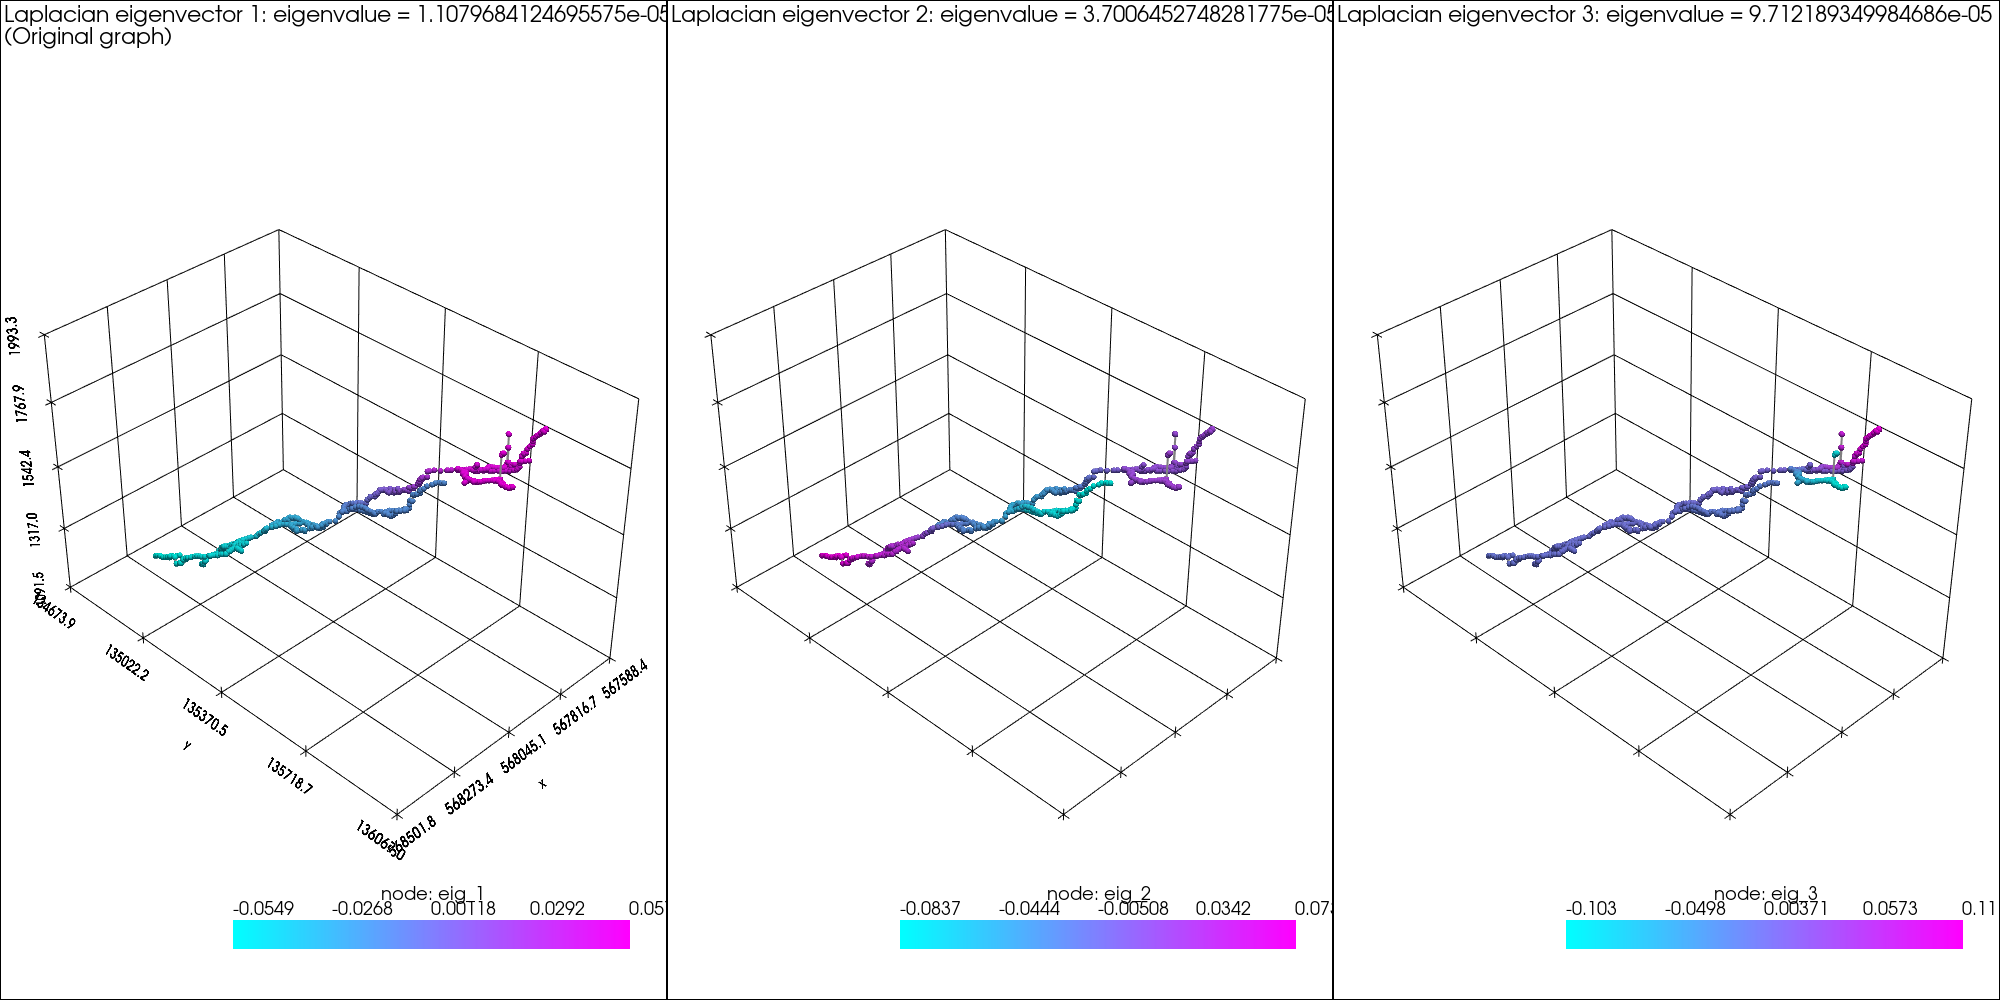

In [37]:
#pp = pv.Plotter(shape=(1, 3), window_size=(2000, 1000), notebook=False) # plot in a pop-up window
pp = pv.Plotter(shape=(1, 3), window_size=(2000, 1000))

for j in range(1, 4):
    pp.subplot(0, j-1)
    kn.view.pv_plot_graph(
        g, 
        plotter=pp,
        node_attr=f'eig_{j}',
        options_nodes={'point_size': 6, 'cmap': 'cool'},
        options_edges={'line_width': 2, 'color': 'gray'},
        show_grid=True,
        options_show_grid={'font_size': 12, 'padding': 0.2},
        with_labels=False
    )
    if j==1:
        pp.add_text(f'Laplacian eigenvector {j}: eigenvalue = {eigval[j]}\n(Original graph)', font_size=16)
    else:
        pp.add_text(f'Laplacian eigenvector {j}: eigenvalue = {eigval[j]}', font_size=16)

pp.link_views()
pp.show()
